# Experiment 8: Multi-Agent Task Allocation and Coordination

### Agent Setup

In [10]:
import matplotlib.pyplot as plt
import copy

tasks = {
    "T1": "Warehouse",
    "T2": "Mall",
    "T3": "Warehouse",
    "T4": "Hospital",
    "T5": "Station",
    "T6": "Mall",
}

cost_table = {
    "A1": {"T1": 20, "T2": 35, "T3": 30, "T4": 15, "T5": 26, "T6": 21},
    "A2": {"T1": 25, "T2": 20, "T3": 22, "T4": 27, "T5": 19, "T6": 30},
    "A3": {"T1": 30, "T2": 28, "T3": 18, "T4": 33, "T5": 24, "T6": 17},
}

MAX_TASKS = 3  

In [11]:
class DeliveryAgent:
    def __init__(self, name, costs, max_tasks=MAX_TASKS):
        self.name = name
        self.costs = costs            # dictionary {task: cost}
        self.max_tasks = max_tasks
        self.assigned = []            

    def make_bid(self, task):
        
        if len(self.assigned) >= self.max_tasks:
            return None
        return self.costs[task]

    def total_cost(self):
        return sum(self.costs[t] for t in self.assigned)


class ManagerAgent:
    def __init__(self, agents):
        self.agents = agents
        self.allocation = {}          # {task: (agent, cost)}

    def announce_task(self, task):
        print(f"[Manager] Task announcement: {task} at {tasks[task]}")
        return task

    def collect_bids(self, task):
        bids = {}
        for agent in self.agents:
            b = agent.make_bid(task)
            if b is not None:
                bids[agent.name] = b
                print(f"   Bid from {agent.name}: {b} min")
            else:
                print(f"   {agent.name} did not bid (already full)")
        return bids

    def select_agent(self, bids):
        best_agent = min(bids, key=bids.get)
        return best_agent, bids[best_agent]

    def assign_task(self, task, agent_name, cost):
        for a in self.agents:
            if a.name == agent_name:
                a.assigned.append(task)
        self.allocation[task] = (agent_name, cost)
        print(f"[Manager] {task} assigned to {agent_name} (cost = {cost})\n")

In [12]:
def create_agents(table):
    return [DeliveryAgent(name, costs) for name, costs in table.items()]

agents = create_agents(cost_table)
manager = ManagerAgent(agents)

print("Manager agent created: 1")
print("Delivery agents created:", [a.name for a in agents])
print("Number of tasks:", len(tasks))

print("\nCost table (minutes)")
print("Task  Location    " + "   ".join(cost_table.keys()))
for t in tasks:
    row = "   ".join(f"{cost_table[a][t]:>2}" for a in cost_table)
    print(f"{t:<5} {tasks[t]:<11} {row}")

Manager agent created: 1
Delivery agents created: ['A1', 'A2', 'A3']
Number of tasks: 6

Cost table (minutes)
Task  Location    A1   A2   A3
T1    Warehouse   20   25   30
T2    Mall        35   20   28
T3    Warehouse   30   22   18
T4    Hospital    15   27   33
T5    Station     26   19   24
T6    Mall        21   30   17


## PGP Coordination


In [13]:
local_plans = {
    "A1": [("T1", "Warehouse", 0, 20),
           ("T4", "Hospital", 20, 35)],
    "A2": [("T3", "Warehouse", 10, 32),     
           ("T5", "Station", 32, 51)],
    "A3": [("T6", "Mall", 0, 17),
           ("T2", "Mall", 17, 45)],
}

def show_plans(plans):
    for agent, plan in plans.items():
        print(agent, ":")
        for (t, loc, s, e) in plan:
            print(f"    {t} at {loc:<10} time {s} to {e}")

print("Local plans before PGP:")
show_plans(local_plans)

Local plans before PGP:
A1 :
    T1 at Warehouse  time 0 to 20
    T4 at Hospital   time 20 to 35
A2 :
    T3 at Warehouse  time 10 to 32
    T5 at Station    time 32 to 51
A3 :
    T6 at Mall       time 0 to 17
    T2 at Mall       time 17 to 45


In [14]:
def find_conflicts(plans):
    conflicts = []
    names = list(plans.keys())
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            for a in plans[names[i]]:
                for b in plans[names[j]]:
                    same_place = (a[1] == b[1])
                    overlap = (a[2] < b[3]) and (b[2] < a[3])
                    if same_place and overlap:
                        conflicts.append((names[i], a, names[j], b))
    return conflicts


def resolve_conflicts(plans):
    plans = copy.deepcopy(plans)

    while True:
        conflicts = find_conflicts(plans)
        if not conflicts:
            break
        n1, e1, n2, e2 = conflicts[0]

        if e1[2] <= e2[2]:
            first_end, wait_agent, wait_entry = e1[3], n2, e2
        else:
            first_end, wait_agent, wait_entry = e2[3], n1, e1
        delay = first_end - wait_entry[2]
        
        print(f"Conflict found at {e1[1]}: {n1}({e1[0]}) and {n2}({e2[0]}) overlap")
        print(f"   -> {wait_agent} will wait {delay} min, its plan is shifted")
        # shift this task and all tasks after it in that agent's plan
        new_plan = []
        shift = False
        for entry in plans[wait_agent]:
            if entry == wait_entry:
                shift = True
            if shift:
                entry = (entry[0], entry[1], entry[2] + delay, entry[3] + delay)
            new_plan.append(entry)
        plans[wait_agent] = new_plan
    return plans


conflicts = find_conflicts(local_plans)
print("Number of conflicts detected:", len(conflicts))
for c in conflicts:
    print(f"  {c[0]} {c[1]}  <-->  {c[2]} {c[3]}")
print()

resolved_plans = resolve_conflicts(local_plans)

print("\nPlans after PGP:")
show_plans(resolved_plans)
print("\nConflicts remaining:", len(find_conflicts(resolved_plans)))

Number of conflicts detected: 1
  A1 ('T1', 'Warehouse', 0, 20)  <-->  A2 ('T3', 'Warehouse', 10, 32)

Conflict found at Warehouse: A1(T1) and A2(T3) overlap
   -> A2 will wait 10 min, its plan is shifted

Plans after PGP:
A1 :
    T1 at Warehouse  time 0 to 20
    T4 at Hospital   time 20 to 35
A2 :
    T3 at Warehouse  time 20 to 42
    T5 at Station    time 42 to 61
A3 :
    T6 at Mall       time 0 to 17
    T2 at Mall       time 17 to 45

Conflicts remaining: 0


## CNP Task Allocation
Contract Net Protocol steps:

**Task Announcement -> Bidding -> Bid Comparison -> Agent Selection -> Task Assignment**

In [15]:
# fresh agents for the demo
demo_agents = create_agents(cost_table)
demo_manager = ManagerAgent(demo_agents)

task = "T1"

print("STEP 1: Task Announcement")
demo_manager.announce_task(task)

print("\nSTEP 2: Bidding")
bids = demo_manager.collect_bids(task)

print("\nSTEP 3: Bid Comparison")
for name, b in sorted(bids.items(), key=lambda x: x[1]):
    print(f"   {name} -> {b}")

print("\nSTEP 4: Agent Selection")
winner, win_cost = demo_manager.select_agent(bids)
print(f"   Lowest bid is {win_cost} by {winner}")

print("\nSTEP 5: Task Assignment")
demo_manager.assign_task(task, winner, win_cost)

STEP 1: Task Announcement
[Manager] Task announcement: T1 at Warehouse

STEP 2: Bidding
   Bid from A1: 20 min
   Bid from A2: 25 min
   Bid from A3: 30 min

STEP 3: Bid Comparison
   A1 -> 20
   A2 -> 25
   A3 -> 30

STEP 4: Agent Selection
   Lowest bid is 20 by A1

STEP 5: Task Assignment
[Manager] T1 assigned to A1 (cost = 20)



## Multiple Task Allocation
Now the manager runs CNP for all 6 tasks one by one. Since an agent can only take 3 tasks, agents who are full do not bid anymore.

In [16]:
def run_cnp(table, verbose=True):
    ags = create_agents(table)
    mgr = ManagerAgent(ags)
    for t in tasks:
        mgr.announce_task(t)
        bids = mgr.collect_bids(t)
        winner, c = mgr.select_agent(bids)
        mgr.assign_task(t, winner, c)
    return ags, mgr


agents, manager = run_cnp(cost_table)

[Manager] Task announcement: T1 at Warehouse
   Bid from A1: 20 min
   Bid from A2: 25 min
   Bid from A3: 30 min
[Manager] T1 assigned to A1 (cost = 20)

[Manager] Task announcement: T2 at Mall
   Bid from A1: 35 min
   Bid from A2: 20 min
   Bid from A3: 28 min
[Manager] T2 assigned to A2 (cost = 20)

[Manager] Task announcement: T3 at Warehouse
   Bid from A1: 30 min
   Bid from A2: 22 min
   Bid from A3: 18 min
[Manager] T3 assigned to A3 (cost = 18)

[Manager] Task announcement: T4 at Hospital
   Bid from A1: 15 min
   Bid from A2: 27 min
   Bid from A3: 33 min
[Manager] T4 assigned to A1 (cost = 15)

[Manager] Task announcement: T5 at Station
   Bid from A1: 26 min
   Bid from A2: 19 min
   Bid from A3: 24 min
[Manager] T5 assigned to A2 (cost = 19)

[Manager] Task announcement: T6 at Mall
   Bid from A1: 21 min
   Bid from A2: 30 min
   Bid from A3: 17 min
[Manager] T6 assigned to A3 (cost = 17)



In [17]:
def show_allocation(mgr):
    print(f"{'Task':<6}| {'Selected Agent':<15}| Cost/Time")
    print("-" * 36)
    for t, (a, c) in mgr.allocation.items():
        print(f"{t:<6}| {a:<15}| {c}")
    total = sum(c for (a, c) in mgr.allocation.values())
    print("-" * 36)
    print("Total cost/time =", total, "minutes")
    return total

total_original = show_allocation(manager)

print("\nAgent wise cost:")
original_costs = {}
for a in agents:
    original_costs[a.name] = a.total_cost()
    print(f"  {a.name}: tasks = {a.assigned}, total = {a.total_cost()}")

Task  | Selected Agent | Cost/Time
------------------------------------
T1    | A1             | 20
T2    | A2             | 20
T3    | A3             | 18
T4    | A1             | 15
T5    | A2             | 19
T6    | A3             | 17
------------------------------------
Total cost/time = 109 minutes

Agent wise cost:
  A1: tasks = ['T1', 'T4'], total = 35
  A2: tasks = ['T2', 'T5'], total = 39
  A3: tasks = ['T3', 'T6'], total = 35


In [18]:
def make_plans_from_allocation(ags):
    plans = {}
    for a in ags:
        time = 0
        plan = []
        for t in a.assigned:
            plan.append((t, tasks[t], time, time + a.costs[t]))
            time += a.costs[t]
        plans[a.name] = plan
    return plans

final_plans = make_plans_from_allocation(agents)
print("Plans from CNP allocation:")
show_plans(final_plans)

print()
final_plans = resolve_conflicts(final_plans)
print("\nFinal plans after PGP check:")
show_plans(final_plans)

Plans from CNP allocation:
A1 :
    T1 at Warehouse  time 0 to 20
    T4 at Hospital   time 20 to 35
A2 :
    T2 at Mall       time 0 to 20
    T5 at Station    time 20 to 39
A3 :
    T3 at Warehouse  time 0 to 18
    T6 at Mall       time 18 to 35

Conflict found at Warehouse: A1(T1) and A3(T3) overlap
   -> A3 will wait 20 min, its plan is shifted

Final plans after PGP check:
A1 :
    T1 at Warehouse  time 0 to 20
    T4 at Hospital   time 20 to 35
A2 :
    T2 at Mall       time 0 to 20
    T5 at Station    time 20 to 39
A3 :
    T3 at Warehouse  time 20 to 38
    T6 at Mall       time 38 to 55


##  Modification & Visualization


In [19]:

new_cost_table = copy.deepcopy(cost_table)
new_cost_table["A1"]["T1"] = 38
new_cost_table["A1"]["T4"] = 30
new_cost_table["A1"]["T6"] = 14
new_cost_table["A3"]["T2"] = 15

print("Modified cost table (minutes)")
print("Task  Location    " + "   ".join(new_cost_table.keys()))
for t in tasks:
    row = "   ".join(f"{new_cost_table[a][t]:>2}" for a in new_cost_table)
    print(f"{t:<5} {tasks[t]:<11} {row}")
print()

Modified cost table (minutes)
Task  Location    A1   A2   A3
T1    Warehouse   38   25   30
T2    Mall        35   20   15
T3    Warehouse   30   22   18
T4    Hospital    30   27   33
T5    Station     26   19   24
T6    Mall        14   30   17



In [20]:
new_agents, new_manager = run_cnp(new_cost_table)

[Manager] Task announcement: T1 at Warehouse
   Bid from A1: 38 min
   Bid from A2: 25 min
   Bid from A3: 30 min
[Manager] T1 assigned to A2 (cost = 25)

[Manager] Task announcement: T2 at Mall
   Bid from A1: 35 min
   Bid from A2: 20 min
   Bid from A3: 15 min
[Manager] T2 assigned to A3 (cost = 15)

[Manager] Task announcement: T3 at Warehouse
   Bid from A1: 30 min
   Bid from A2: 22 min
   Bid from A3: 18 min
[Manager] T3 assigned to A3 (cost = 18)

[Manager] Task announcement: T4 at Hospital
   Bid from A1: 30 min
   Bid from A2: 27 min
   Bid from A3: 33 min
[Manager] T4 assigned to A2 (cost = 27)

[Manager] Task announcement: T5 at Station
   Bid from A1: 26 min
   Bid from A2: 19 min
   Bid from A3: 24 min
[Manager] T5 assigned to A2 (cost = 19)

[Manager] Task announcement: T6 at Mall
   Bid from A1: 14 min
   A2 did not bid (already full)
   Bid from A3: 17 min
[Manager] T6 assigned to A1 (cost = 14)



In [21]:
total_new = show_allocation(new_manager)

new_costs = {}
print("\nAgent wise cost:")
for a in new_agents:
    new_costs[a.name] = a.total_cost()
    print(f"  {a.name}: tasks = {a.assigned}, total = {a.total_cost()}")

# PGP check on the new allocation also
new_plans = make_plans_from_allocation(new_agents)
print("\nPlans for modified run (after PGP check):")
show_plans(resolve_conflicts(new_plans))

Task  | Selected Agent | Cost/Time
------------------------------------
T1    | A2             | 25
T2    | A3             | 15
T3    | A3             | 18
T4    | A2             | 27
T5    | A2             | 19
T6    | A1             | 14
------------------------------------
Total cost/time = 118 minutes

Agent wise cost:
  A1: tasks = ['T6'], total = 14
  A2: tasks = ['T1', 'T4', 'T5'], total = 71
  A3: tasks = ['T2', 'T3'], total = 33

Plans for modified run (after PGP check):
Conflict found at Mall: A1(T6) and A3(T2) overlap
   -> A3 will wait 14 min, its plan is shifted
A1 :
    T6 at Mall       time 0 to 14
A2 :
    T1 at Warehouse  time 0 to 25
    T4 at Hospital   time 25 to 52
    T5 at Station    time 52 to 71
A3 :
    T2 at Mall       time 14 to 29
    T3 at Warehouse  time 29 to 47


In [25]:
# comparing both runs
print(f"{'Task':<6}| {'Before':<8}| {'After':<8}")
print("-" * 26)
for t in tasks:
    b = manager.allocation[t][0]
    a = new_manager.allocation[t][0]
    flag = "" if a == b else "  <- changed"
    print(f"{t:<6}| {b:<8}| {a:<8}{flag}")

print("\nTotal before:", total_original)
print("Total after :", total_new)
print("Difference  :", total_new - total_original)

Task  | Before  | After   
--------------------------
T1    | A1      | A2        <- changed
T2    | A2      | A3        <- changed
T3    | A3      | A3      
T4    | A1      | A2        <- changed
T5    | A2      | A2      
T6    | A3      | A1        <- changed

Total before: 109
Total after : 118
Difference  : 9


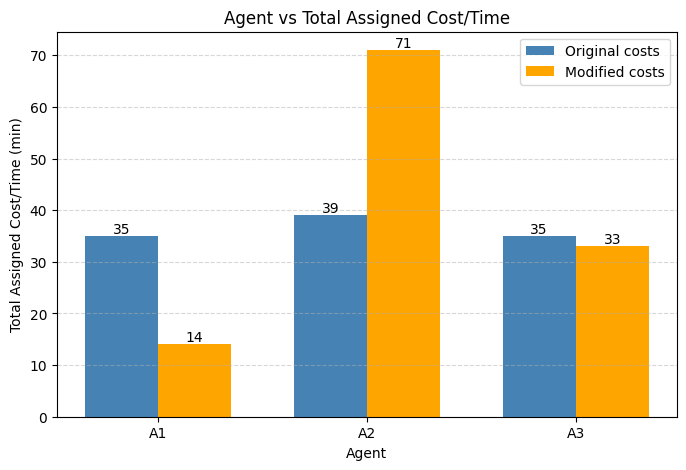

In [23]:
# plot agent vs total assigned cost
names = list(original_costs.keys())
before = [original_costs[n] for n in names]
after = [new_costs[n] for n in names]

x = range(len(names))
width = 0.35

plt.figure(figsize=(8, 5))
bars1 = plt.bar([i - width/2 for i in x], before, width, label="Original costs", color="steelblue")
bars2 = plt.bar([i + width/2 for i in x], after, width, label="Modified costs", color="orange")

# writing values on top of bars
for bar in list(bars1) + list(bars2):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             str(int(bar.get_height())), ha="center")

plt.xticks(list(x), names)
plt.xlabel("Agent")
plt.ylabel("Total Assigned Cost/Time (min)")
plt.title("Agent vs Total Assigned Cost/Time")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()